# Modelagem Preditiva de Reincidencia da Violencia Contra a Mulher

## Objetivo

Este notebook tem como objetivo desenvolver uma analise inicial para modelagem preditiva de reincidencia da violencia contra a mulher com base nos registros do SINAN/DATASUS.

A proposta e utilizar variaveis relacionadas ao perfil da vitima, caracteristicas da violencia, contexto da ocorrencia e informacoes sobre o agressor para identificar padroes associados a casos com maior probabilidade estatistica de reincidencia.

O problema sera tratado como uma tarefa de **classificacao binaria**.

## Variavel Alvo

A variavel alvo definida para o modelo e:

`OUT_VEZES`

Interpretacao adotada:

- `1` = houve reincidencia
- `0` = nao houve reincidencia

Assim, o modelo buscara aprender, a partir dos dados historicos, quais combinacoes de caracteristicas aparecem com maior frequencia em registros associados a reincidencia.

## Observacao Importante

O modelo nao deve ser interpretado como instrumento de diagnostico ou decisao automatica. Seu uso potencial e como apoio a triagem, priorizacao de acompanhamento e suporte a profissionais da rede de protecao, mantendo a decisao final sob responsabilidade humana.

## Imports

In [1]:
from pathlib import Path
import builtins

import numpy as np
import matplotlib.pyplot as plt
import shap
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

d:\Estudos\IA\fiap-tech-chalange-2-ia-para-devs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Leitura da Base

Nesta etapa, a leitura segue uma versao simplificada da logica usada no script `01_selecionar_variaveis.py`:

- localizar o arquivo bruto disponivel no projeto;
- ler o dataset;
- filtrar apenas registros de mulheres (`CS_SEXO == "F"`);
- manter somente as colunas selecionadas para o projeto.

In [2]:
COLUNAS = [
    "NU_IDADE_N",
    "CS_RACA",
    "CS_ESCOL_N",
    "SIT_CONJUG",
    "CS_GESTANT",
    "DEF_TRANS",
    "DEF_FISICA",
    "DEF_MENTAL",
    "DEF_VISUAL",
    "DEF_AUDITI",
    "TRAN_MENT",
    "SG_UF",
    "LOCAL_OCOR",
    "VIOL_FISIC",
    "VIOL_PSICO",
    "VIOL_SEXU",
    "VIOL_NEGLI",
    "VIOL_FINAN",
    "VIOL_TORT",
    "LES_AUTOP",
    "AG_FORCA",
    "AG_CORTE",
    "AG_FOGO",
    "AG_AMEACA",
    "REL_CONJ",
    "REL_EXCON",
    "REL_NAMO",
    "REL_PAI",
    "REL_MAE",
    "AUTOR_SEXO",
    "AUTOR_ALCO",
    "NUM_ENVOLV",
    "OUT_VEZES",
]

raiz_projeto = Path("..").resolve()
arquivo_csv = raiz_projeto / "data" / "raw" / "VIOLBR25_ptbr.csv"
arquivo_xlsx = raiz_projeto / "data" / "raw" / "VIOLBR25.xlsx"

if arquivo_csv.exists():
    df_bruto = pd.read_csv(arquivo_csv, sep=";", low_memory=False)
elif arquivo_xlsx.exists():
    df_bruto = pd.read_excel(arquivo_xlsx)
else:
    raise FileNotFoundError("Nenhum arquivo bruto encontrado em data/raw.")

df = df_bruto[df_bruto["CS_SEXO"] == "F"].copy()
df = df[COLUNAS].copy()

print(f"Registros: {len(df):,}")
print(f"Colunas: {len(df.columns)}")
df.head()

Registros: 477,994
Colunas: 33


,NU_IDADE_N,CS_RACA,CS_ESCOL_N,SIT_CONJUG,CS_GESTANT,DEF_TRANS,DEF_FISICA,DEF_MENTAL,DEF_VISUAL,DEF_AUDITI,...,AG_AMEACA,REL_CONJ,REL_EXCON,REL_NAMO,REL_PAI,REL_MAE,AUTOR_SEXO,AUTOR_ALCO,NUM_ENVOLV,OUT_VEZES
0,4046,1.0,7.0,3.0,5.0,2.0,8.0,8.0,8.0,8.0,...,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0
1,4019,4.0,9.0,1.0,5.0,2.0,8.0,8.0,8.0,8.0,...,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0
4,4084,1.0,9.0,9.0,5.0,2.0,8.0,8.0,8.0,8.0,...,2.0,2.0,2.0,2.0,2.0,2.0,9.0,9.0,1.0,1.0
5,4052,1.0,9.0,2.0,9.0,9.0,8.0,8.0,8.0,8.0,...,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0
7,4039,4.0,6.0,2.0,5.0,2.0,8.0,8.0,8.0,8.0,...,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0


## Diagnostico de Nulos e Inconsistencias

Antes de limpar a base, vale verificar nulos, codigos suspeitos e a distribuicao inicial da variavel alvo.

In [3]:
codigos_suspeitos = {9, 99, 999, 9999, "9", "99", "999", "9999", "Ignorado", "Nao informado", "Em branco", ""}

resumo_qualidade = pd.DataFrame({
    "coluna": df.columns,
    "tipo": [str(df[coluna].dtype) for coluna in df.columns],
    "qtd_nulos": [df[coluna].isna().sum() for coluna in df.columns],
    "pct_nulos": [round(df[coluna].isna().mean() * 100, 2) for coluna in df.columns],
    "qtd_valores_unicos": [df[coluna].nunique(dropna=True) for coluna in df.columns],
    "qtd_codigos_suspeitos": [df[coluna].isin(codigos_suspeitos).sum() for coluna in df.columns],
})

resumo_qualidade.sort_values(by=["pct_nulos", "qtd_codigos_suspeitos"], ascending=False).head(15)

,coluna,tipo,qtd_nulos,pct_nulos,qtd_valores_unicos,qtd_codigos_suspeitos
22,AG_FOGO,float64,25904,5.42,3,9249
21,AG_CORTE,float64,25251,5.28,3,8995
23,AG_AMEACA,float64,25040,5.24,3,9774
3,SIT_CONJUG,float64,24892,5.21,6,59736
9,DEF_AUDITI,float64,23635,4.94,4,1967
7,DEF_MENTAL,float64,23579,4.93,4,2119
8,DEF_VISUAL,float64,23570,4.93,4,1964
6,DEF_FISICA,float64,23535,4.92,4,1900
26,REL_NAMO,float64,22780,4.77,3,15241
31,NUM_ENVOLV,float64,22733,4.76,3,20259


In [4]:
df["OUT_VEZES"].value_counts(dropna=False)

OUT_VEZES
1.0    202170
2.0    166631
9.0     87181
NaN     22012
Name: count, dtype: int64

## Tratamento Inicial da Base

Agora convertemos codigos de ignorado para `NaN` e tratamos `OUT_VEZES` como alvo binario.

In [5]:
CODIGOS_IGNORADOS = {
    "CS_RACA": [9],
    "CS_ESCOL_N": [9],
    "SIT_CONJUG": [9],
    "CS_GESTANT": [9],
    "DEF_TRANS": [9],
    "DEF_FISICA": [9],
    "DEF_MENTAL": [9],
    "DEF_VISUAL": [9],
    "DEF_AUDITI": [9],
    "TRAN_MENT": [9],
    "LOCAL_OCOR": [9, 99],
    "VIOL_FISIC": [9],
    "VIOL_PSICO": [9],
    "VIOL_SEXU": [9],
    "VIOL_NEGLI": [9],
    "VIOL_FINAN": [9],
    "VIOL_TORT": [9],
    "LES_AUTOP": [9],
    "AG_FORCA": [9],
    "AG_CORTE": [9],
    "AG_FOGO": [9],
    "AG_AMEACA": [9],
    "REL_CONJ": [9],
    "REL_EXCON": [9],
    "REL_NAMO": [9],
    "REL_PAI": [9],
    "REL_MAE": [9],
    "AUTOR_SEXO": [9],
    "AUTOR_ALCO": [9],
    "NUM_ENVOLV": [9],
}

MAPA_ALVO = {1: 1, 2: 0}

In [6]:
df_tratado = df.copy()

for coluna, codigos in CODIGOS_IGNORADOS.items():
    if coluna in df_tratado.columns:
        df_tratado[coluna] = df_tratado[coluna].replace(codigos, pd.NA)

df_tratado = df_tratado[df_tratado["OUT_VEZES"].isin(MAPA_ALVO.keys())].copy()
df_tratado["OUT_VEZES"] = df_tratado["OUT_VEZES"].map(MAPA_ALVO).astype("int64")

print(f"Registros antes do tratamento: {len(df):,}")
print(f"Registros depois do tratamento: {len(df_tratado):,}")
df_tratado.head()

Registros antes do tratamento: 477,994
Registros depois do tratamento: 368,801


,NU_IDADE_N,CS_RACA,CS_ESCOL_N,SIT_CONJUG,CS_GESTANT,DEF_TRANS,DEF_FISICA,DEF_MENTAL,DEF_VISUAL,DEF_AUDITI,...,AG_AMEACA,REL_CONJ,REL_EXCON,REL_NAMO,REL_PAI,REL_MAE,AUTOR_SEXO,AUTOR_ALCO,NUM_ENVOLV,OUT_VEZES
0,4046,1.0,7.0,3.0,5.0,2.0,8.0,8.0,8.0,8.0,...,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,0
1,4019,4.0,<NA>,1.0,5.0,2.0,8.0,8.0,8.0,8.0,...,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1
4,4084,1.0,<NA>,<NA>,5.0,2.0,8.0,8.0,8.0,8.0,...,2.0,2.0,2.0,2.0,2.0,2.0,<NA>,<NA>,1.0,1
5,4052,1.0,<NA>,2.0,<NA>,<NA>,8.0,8.0,8.0,8.0,...,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,0
7,4039,4.0,6.0,2.0,5.0,2.0,8.0,8.0,8.0,8.0,...,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,0


### Verificacao da Variavel Alvo Apos o Tratamento

In [7]:
df_tratado["OUT_VEZES"].value_counts(dropna=False)

OUT_VEZES
1    202170
0    166631
Name: count, dtype: int64

### Resumo de Nulos Apos o Tratamento Inicial

In [8]:
resumo_pos_tratamento = pd.DataFrame({
    "coluna": df_tratado.columns,
    "qtd_nulos": [df_tratado[coluna].isna().sum() for coluna in df_tratado.columns],
    "pct_nulos": [round(df_tratado[coluna].isna().mean() * 100, 2) for coluna in df_tratado.columns],
})

resumo_pos_tratamento.sort_values(by="pct_nulos", ascending=False).head(15)

,coluna,qtd_nulos,pct_nulos
2,CS_ESCOL_N,84383,22.88
30,AUTOR_ALCO,67351,18.26
3,SIT_CONJUG,33951,9.21
12,LOCAL_OCOR,33144,8.99
5,DEF_TRANS,28977,7.86
4,CS_GESTANT,25835,7.01
29,AUTOR_SEXO,12980,3.52
31,NUM_ENVOLV,11326,3.07
22,AG_FOGO,9667,2.62
21,AG_CORTE,9030,2.45


## Limpeza Fina

Nesta etapa, fazemos uma revisao adicional antes da modelagem.

In [9]:
IDADE_MINIMA = 0
IDADE_MAXIMA = 120
LIMITE_NULOS_EXCLUSAO = 30.0

df_limpo = df_tratado.copy()

if "NU_IDADE_N" in df_limpo.columns:
    mascara_idade_invalida = (
        (df_limpo["NU_IDADE_N"] < IDADE_MINIMA)
        | (df_limpo["NU_IDADE_N"] > IDADE_MAXIMA)
    )
    df_limpo.loc[mascara_idade_invalida, "NU_IDADE_N"] = pd.NA

percentuais_nulos = (df_limpo.isna().mean() * 100).round(2)
colunas_removidas = percentuais_nulos[percentuais_nulos > LIMITE_NULOS_EXCLUSAO].index.tolist()
df_limpo = df_limpo.drop(columns=colunas_removidas, errors="ignore")

print(f"Colunas removidas: {colunas_removidas if colunas_removidas else 'nenhuma'}")
print(f"Formato final da base limpa: {df_limpo.shape}")

Colunas removidas: ['NU_IDADE_N']
Formato final da base limpa: (368801, 32)


In [10]:
pd.DataFrame({
    "coluna": percentuais_nulos.index,
    "pct_nulos": percentuais_nulos.values,
    "removida": percentuais_nulos.index.isin(colunas_removidas),
}).sort_values(by="pct_nulos", ascending=False).head(15)

,coluna,pct_nulos,removida
0,NU_IDADE_N,100.00,True
2,CS_ESCOL_N,22.88,False
30,AUTOR_ALCO,18.26,False
3,SIT_CONJUG,9.21,False
12,LOCAL_OCOR,8.99,False
5,DEF_TRANS,7.86,False
4,CS_GESTANT,7.01,False
29,AUTOR_SEXO,3.52,False
31,NUM_ENVOLV,3.07,False
22,AG_FOGO,2.62,False


## Definicao do Problema e Divisao Treino/Teste

In [11]:
X = df_limpo.drop(columns=["OUT_VEZES"]).copy()
y = df_limpo["OUT_VEZES"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (295040, 31)
X_test: (73761, 31)
y_train: (295040,)
y_test: (73761,)


In [12]:
resumo_divisao = pd.DataFrame([
    {
        "registros_treino": len(X_train),
        "registros_teste": len(X_test),
        "classe_0_treino": int((y_train == 0).sum()),
        "classe_1_treino": int((y_train == 1).sum()),
        "classe_0_teste": int((y_test == 0).sum()),
        "classe_1_teste": int((y_test == 1).sum()),
    }
])

resumo_divisao

,registros_treino,registros_teste,classe_0_treino,classe_1_treino,classe_0_teste,classe_1_teste
0,295040,73761,133304,161736,33327,40434


## Preparacao Final para o Modelo

In [13]:
print("Nulos em X_train:", X_train.isna().sum().sum())
print("Nulos em X_test:", X_test.isna().sum().sum())
print("Classes y_train:\n", y_train.value_counts(dropna=False).sort_index())
print("Classes y_test:\n", y_test.value_counts(dropna=False).sort_index())

Nulos em X_train: 349207
Nulos em X_test: 87831
Classes y_train:
 OUT_VEZES
0    133304
1    161736
Name: count, dtype: int64
Classes y_test:
 OUT_VEZES
0    33327
1    40434
Name: count, dtype: int64


In [14]:
X_train_modelo = X_train.copy()
X_test_modelo = X_test.copy()

for coluna in X_train_modelo.columns:
    if coluna == "NU_IDADE_N":
        valor_preenchimento = X_train_modelo[coluna].median()
    else:
        moda = X_train_modelo[coluna].mode(dropna=True)
        valor_preenchimento = moda.iloc[0] if not moda.empty else 0

    X_train_modelo[coluna] = X_train_modelo[coluna].fillna(valor_preenchimento)
    X_test_modelo[coluna] = X_test_modelo[coluna].fillna(valor_preenchimento)

print("Nulos em X_train_modelo:", X_train_modelo.isna().sum().sum())
print("Nulos em X_test_modelo:", X_test_modelo.isna().sum().sum())

Nulos em X_train_modelo: 0
Nulos em X_test_modelo: 0


## Modelagem com Arvore de Decisao

In [15]:
modelo_arvore = DecisionTreeClassifier(
    random_state=42,
    max_depth=5,
)

modelo_arvore.fit(X_train_modelo, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [16]:
y_pred = modelo_arvore.predict(X_test_modelo)

pd.DataFrame({
    "y_real": y_test.reset_index(drop=True),
    "y_pred": pd.Series(y_pred).reset_index(drop=True),
}).head(10)

,y_real,y_pred
0,0,1
1,0,1
2,0,0
3,1,0
4,0,1
5,0,0
6,1,1
7,0,0
8,0,0
9,1,0


In [17]:
metricas_arvore = pd.DataFrame([
    {
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "recall": round(recall_score(y_test, y_pred), 4),
        "f1_score": round(f1_score(y_test, y_pred), 4),
    }
])

metricas_arvore

,accuracy,recall,f1_score
0,0.6312,0.5582,0.624


In [18]:
relatorio_classificacao = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0,
    )
).transpose()

relatorio_classificacao

,precision,recall,f1-score,support
0,0.573190,0.719897,0.638221,33327.000000
1,0.707403,0.558169,0.623987,40434.000000
accuracy,0.631241,0.631241,0.631241,0.631241
macro avg,0.640297,0.639033,0.631104,73761.000000
weighted avg,0.646762,0.631241,0.630418,73761.000000


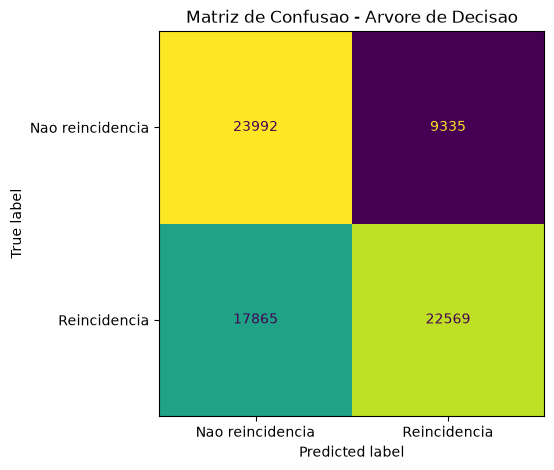

In [19]:
matriz = confusion_matrix(y_test, y_pred)

figura, eixo = plt.subplots(figsize=(6, 5))
display = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Nao reincidencia", "Reincidencia"],
)
display.plot(ax=eixo, colorbar=False)
eixo.set_title("Matriz de Confusao - Arvore de Decisao")
plt.show()

In [20]:
importancias = pd.DataFrame({
    "variavel": X_train_modelo.columns,
    "importancia": modelo_arvore.feature_importances_,
}).sort_values(by="importancia", ascending=False)

importancias.head(10)

,variavel,importancia
11,LOCAL_OCOR,0.225637
13,VIOL_PSICO,0.223177
4,DEF_TRANS,0.192773
23,REL_CONJ,0.099136
1,CS_ESCOL_N,0.076625
18,LES_AUTOP,0.049265
24,REL_EXCON,0.047444
22,AG_AMEACA,0.024815
20,AG_CORTE,0.022608
15,VIOL_NEGLI,0.016385


## Explicabilidade com SHAP - Arvore de Decisao

O SHAP ajuda a mostrar quais variaveis empurram a previsao para reincidencia ou nao reincidencia em cada observacao.


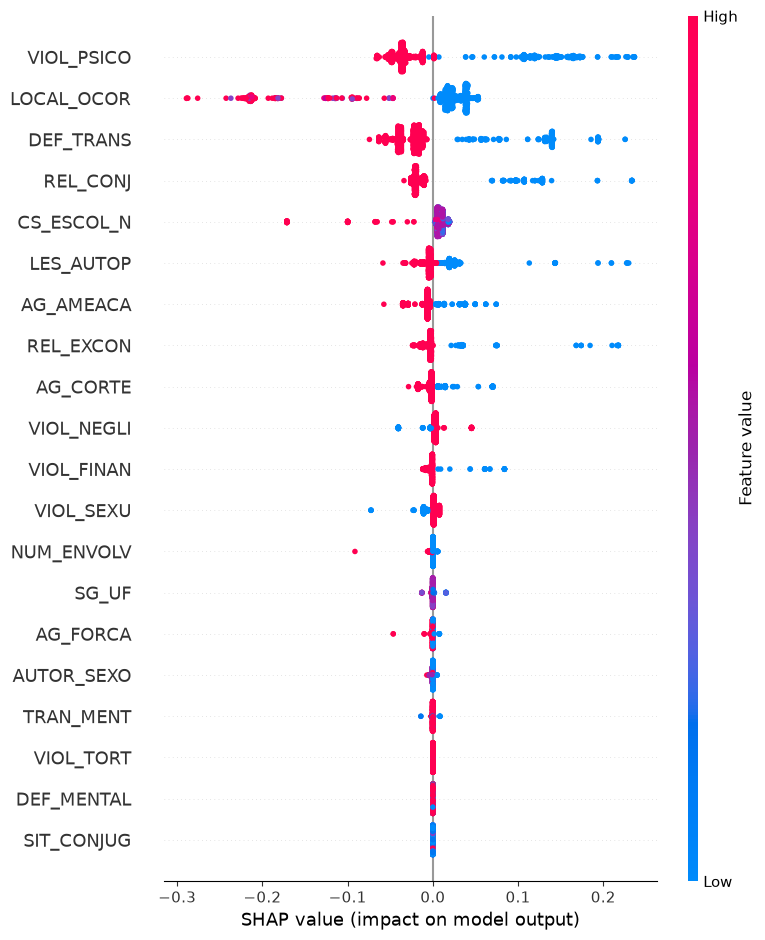

In [21]:
amostra_teste_arvore = X_test_modelo.sample(n=builtins.min(1000, len(X_test_modelo)), random_state=42).copy()
amostra_teste_arvore = amostra_teste_arvore.apply(pd.to_numeric, errors="coerce").astype("float64")

explainer_arvore = shap.TreeExplainer(modelo_arvore)
shap_values_arvore = explainer_arvore.shap_values(amostra_teste_arvore)

if isinstance(shap_values_arvore, list):
    shap_classe_1_arvore = np.asarray(shap_values_arvore[1], dtype="float64")
elif getattr(shap_values_arvore, "ndim", 0) == 3:
    shap_classe_1_arvore = np.asarray(shap_values_arvore[:, :, 1], dtype="float64")
else:
    shap_classe_1_arvore = np.asarray(shap_values_arvore, dtype="float64")

shap.summary_plot(shap_classe_1_arvore, amostra_teste_arvore)


In [22]:
shap_resumo_arvore = pd.DataFrame({
    "variavel": amostra_teste_arvore.columns,
    "mean_abs_shap": abs(shap_classe_1_arvore).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

shap_resumo_arvore.head(10)


,variavel,mean_abs_shap
13,VIOL_PSICO,0.060617
11,LOCAL_OCOR,0.049457
4,DEF_TRANS,0.047061
23,REL_CONJ,0.035370
1,CS_ESCOL_N,0.014878
18,LES_AUTOP,0.014817
22,AG_AMEACA,0.011768
24,REL_EXCON,0.009754
20,AG_CORTE,0.006468
15,VIOL_NEGLI,0.004331


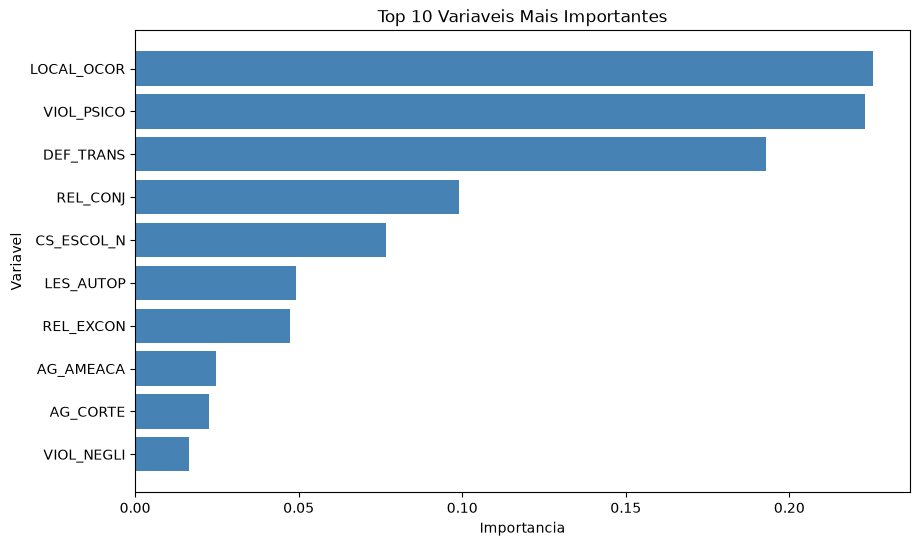

In [23]:
top_importancias = importancias.head(10).iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(top_importancias["variavel"], top_importancias["importancia"], color="steelblue")
plt.title("Top 10 Variaveis Mais Importantes")
plt.xlabel("Importancia")
plt.ylabel("Variavel")
plt.show()

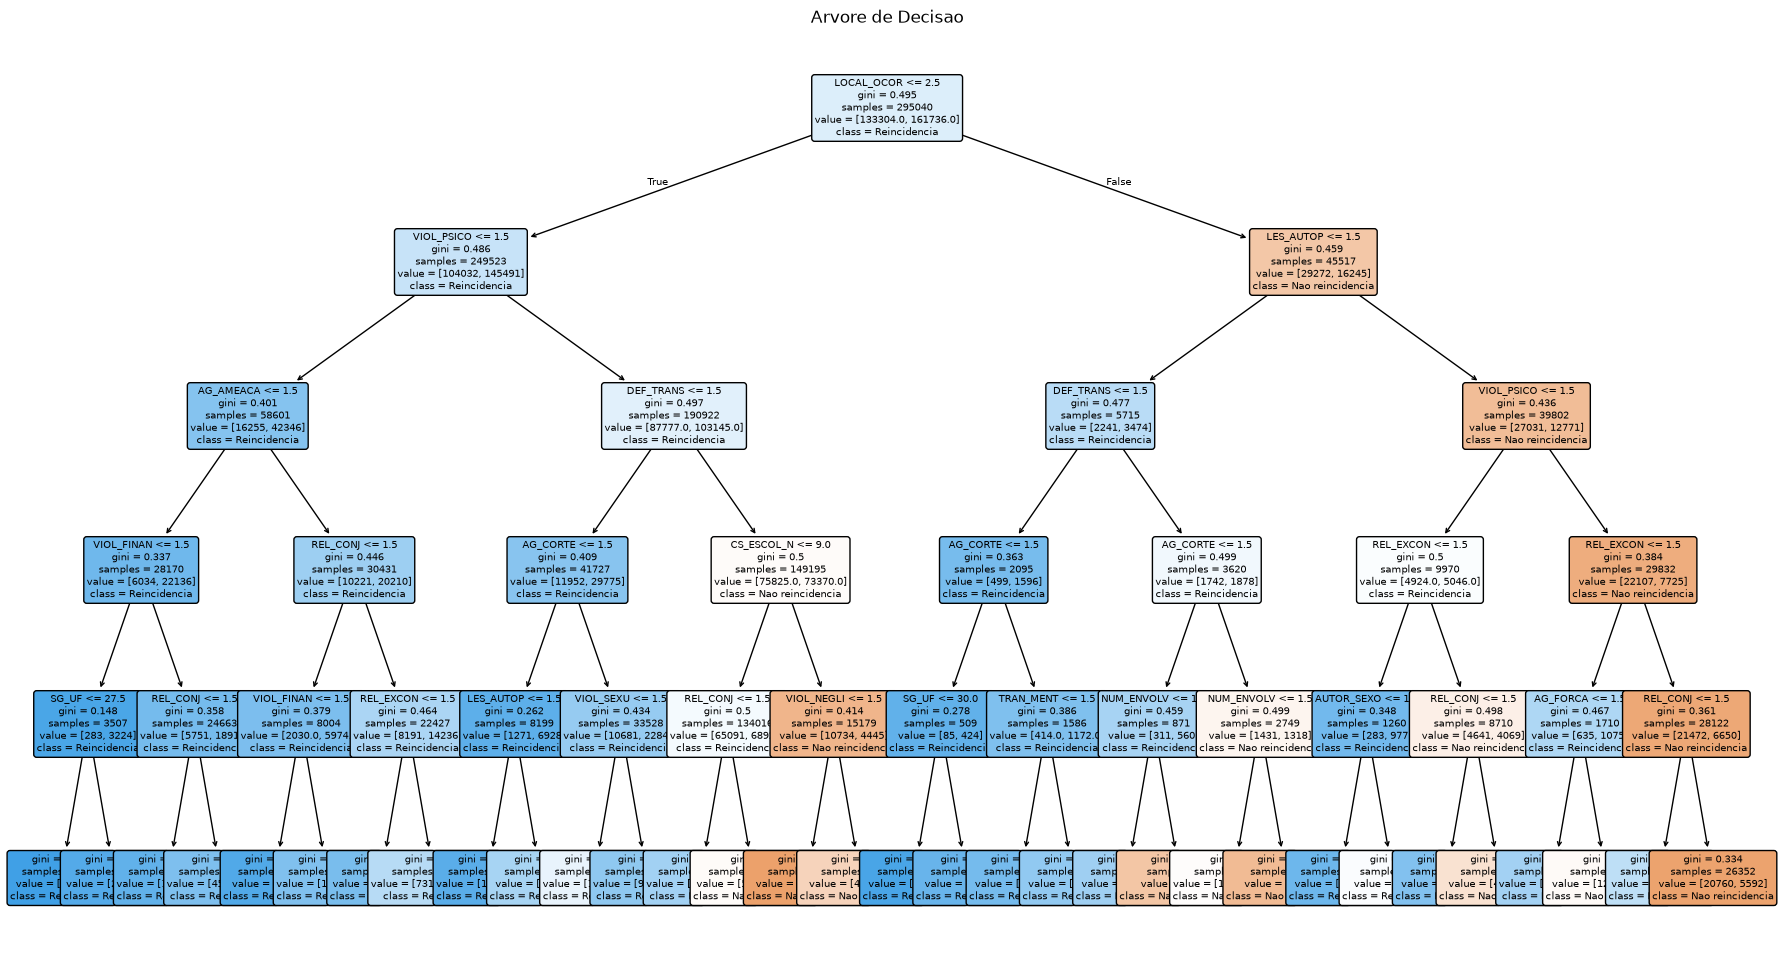

In [24]:
plt.figure(figsize=(22, 12))
plot_tree(
    modelo_arvore,
    feature_names=X_train_modelo.columns,
    class_names=["Nao reincidencia", "Reincidencia"],
    filled=True,
    rounded=True,
    fontsize=7,
)
plt.title("Arvore de Decisao")
plt.show()

## Modelagem com Regressao Logistica

Agora aplicamos um segundo modelo de classificacao para comparar com a Arvore de Decisao.

In [25]:
modelo_logistico = LogisticRegression(
    random_state=42,
    max_iter=1000,
)

modelo_logistico.fit(X_train_modelo, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

## Previsoes da Regressao Logistica

Depois do treino, o modelo gera previsoes para o conjunto de teste. Aqui conseguimos comparar os valores reais com os valores previstos.

In [26]:
y_pred_log = modelo_logistico.predict(X_test_modelo)

pd.DataFrame({
    "y_real": y_test.reset_index(drop=True),
    "y_pred_log": pd.Series(y_pred_log).reset_index(drop=True),
}).head(10)

,y_real,y_pred_log
0,0,1
1,0,1
2,0,0
3,1,0
4,0,1
5,0,0
6,1,1
7,0,0
8,0,0
9,1,0


## Metricas da Regressao Logistica

As mesmas metricas da Arvore de Decisao sao usadas aqui para facilitar a comparacao entre os modelos.

In [27]:
metricas_logistica = pd.DataFrame([
    {
        "accuracy": round(accuracy_score(y_test, y_pred_log), 4),
        "recall": round(recall_score(y_test, y_pred_log), 4),
        "f1_score": round(f1_score(y_test, y_pred_log), 4),
    }
])

metricas_logistica

,accuracy,recall,f1_score
0,0.6588,0.7477,0.7061


## Relatorio de Classificacao

Esse relatorio mostra como a Regressao Logistica se comportou em cada classe, separando precision, recall e f1-score.

In [28]:
relatorio_logistica = pd.DataFrame(
    classification_report(
        y_test,
        y_pred_log,
        output_dict=True,
        zero_division=0,
    )
).transpose()

relatorio_logistica

,precision,recall,f1-score,support
0,0.642865,0.551085,0.593447,33327.000000
1,0.668946,0.747663,0.706117,40434.000000
accuracy,0.658844,0.658844,0.658844,0.658844
macro avg,0.655905,0.649374,0.649782,73761.000000
weighted avg,0.657162,0.658844,0.655210,73761.000000


## Matriz de Confusao - Regressao Logistica

A matriz de confusao ajuda a ver quantos acertos e erros aconteceram em cada classe.

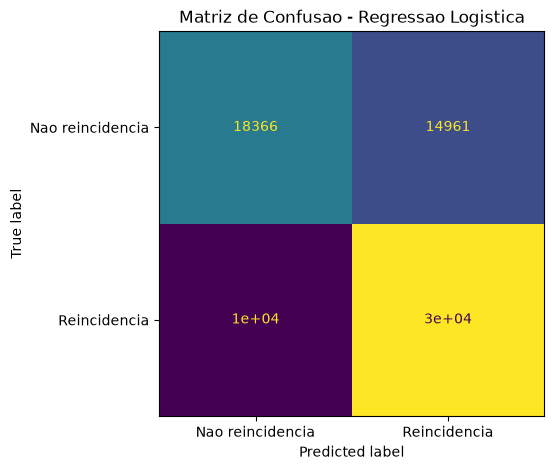

In [29]:
matriz_log = confusion_matrix(y_test, y_pred_log)

figura, eixo = plt.subplots(figsize=(6, 5))
display = ConfusionMatrixDisplay(
    confusion_matrix=matriz_log,
    display_labels=["Nao reincidencia", "Reincidencia"],
)
display.plot(ax=eixo, colorbar=False)
eixo.set_title("Matriz de Confusao - Regressao Logistica")
plt.show()

## Coeficientes Mais Relevantes

Na Regressao Logistica, os coeficientes mostram quais variaveis tiveram mais peso na previsao. Aqui usamos o valor absoluto para destacar a forca da influencia.

In [30]:
coeficientes_log = pd.DataFrame({
    "variavel": X_train_modelo.columns,
    "coeficiente": modelo_logistico.coef_[0],
    "coeficiente_absoluto": abs(modelo_logistico.coef_[0]),
}).sort_values(by="coeficiente_absoluto", ascending=False)

coeficientes_log.head(10)

,variavel,coeficiente,coeficiente_absoluto
24,REL_EXCON,-1.152698,1.152698
23,REL_CONJ,-1.089872,1.089872
16,VIOL_FINAN,-0.986255,0.986255
25,REL_NAMO,-0.816253,0.816253
21,AG_FOGO,0.733150,0.733150
18,LES_AUTOP,-0.639379,0.639379
4,DEF_TRANS,-0.634871,0.634871
22,AG_AMEACA,-0.616876,0.616876
13,VIOL_PSICO,-0.581179,0.581179
20,AG_CORTE,-0.483321,0.483321


## Explicabilidade com SHAP - Regressao Logistica

Na regressao logistica, o SHAP ajuda a complementar a leitura dos coeficientes mostrando o impacto das variaveis nas previsoes individuais.


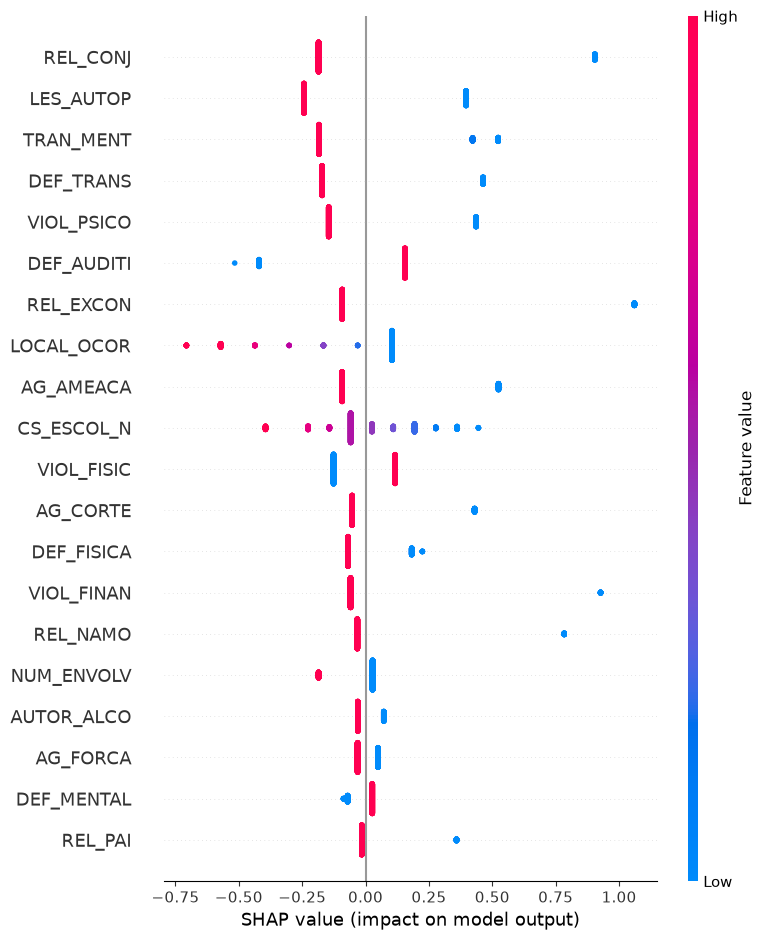

In [31]:
amostra_treino_log = X_train_modelo.sample(n=builtins.min(100, len(X_train_modelo)), random_state=42).copy()
amostra_teste_log = X_test_modelo.sample(n=builtins.min(1000, len(X_test_modelo)), random_state=42).copy()

amostra_treino_log = amostra_treino_log.apply(pd.to_numeric, errors="coerce").astype("float64")
amostra_teste_log = amostra_teste_log.apply(pd.to_numeric, errors="coerce").astype("float64")

explainer_log = shap.LinearExplainer(modelo_logistico, amostra_treino_log)
shap_values_log = explainer_log.shap_values(amostra_teste_log)

if isinstance(shap_values_log, list):
    shap_classe_1_log = np.asarray(shap_values_log[1], dtype="float64")
elif getattr(shap_values_log, "ndim", 0) == 3:
    shap_classe_1_log = np.asarray(shap_values_log[:, :, 1], dtype="float64")
else:
    shap_classe_1_log = np.asarray(shap_values_log, dtype="float64")

shap.summary_plot(shap_classe_1_log, amostra_teste_log)


In [32]:
shap_resumo_log = pd.DataFrame({
    "variavel": amostra_teste_log.columns,
    "mean_abs_shap": abs(shap_classe_1_log).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

shap_resumo_log.head(10)


,variavel,mean_abs_shap
23,REL_CONJ,0.302527
18,LES_AUTOP,0.294063
9,TRAN_MENT,0.239322
4,DEF_TRANS,0.226027
13,VIOL_PSICO,0.217070
8,DEF_AUDITI,0.205044
24,REL_EXCON,0.166772
11,LOCAL_OCOR,0.166694
22,AG_AMEACA,0.165076
1,CS_ESCOL_N,0.126596


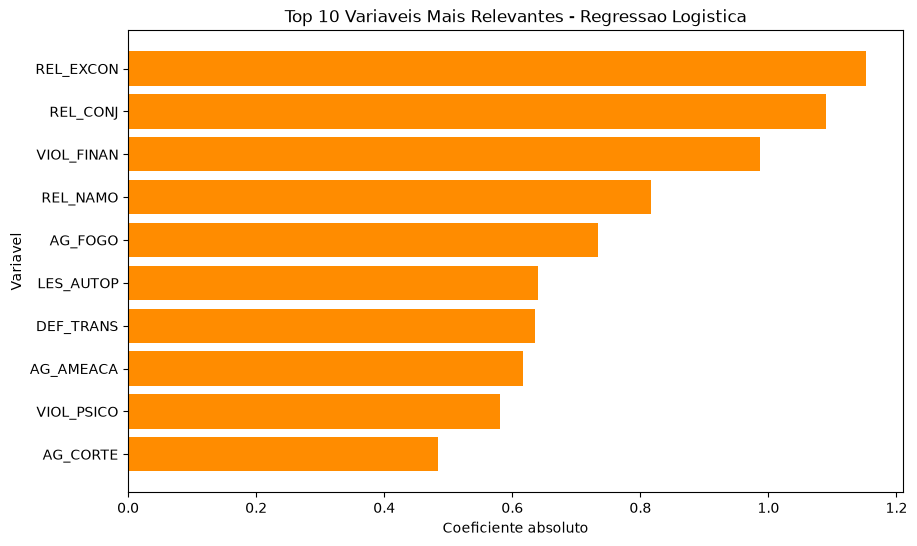

In [33]:
top_coeficientes = coeficientes_log.head(10).iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(top_coeficientes["variavel"], top_coeficientes["coeficiente_absoluto"], color="darkorange")
plt.title("Top 10 Variaveis Mais Relevantes - Regressao Logistica")
plt.xlabel("Coeficiente absoluto")
plt.ylabel("Variavel")
plt.show()

## Comparacao Entre os Modelos

Nesta ultima etapa, colocamos Arvore de Decisao e Regressao Logistica lado a lado para ver qual teve melhor desempenho.

In [34]:
comparacao_modelos = pd.DataFrame([
    {
        "modelo": "Arvore de Decisao",
        "accuracy": metricas_arvore.loc[0, "accuracy"],
        "recall": metricas_arvore.loc[0, "recall"],
        "f1_score": metricas_arvore.loc[0, "f1_score"],
    },
    {
        "modelo": "Regressao Logistica",
        "accuracy": metricas_logistica.loc[0, "accuracy"],
        "recall": metricas_logistica.loc[0, "recall"],
        "f1_score": metricas_logistica.loc[0, "f1_score"],
    }
])

comparacao_modelos

,modelo,accuracy,recall,f1_score
0,Arvore de Decisao,0.6312,0.5582,0.6240
1,Regressao Logistica,0.6588,0.7477,0.7061
